# Churn Prediction Model

## What this notebook does

This notebook builds a model that predicts which customers are likely to stop buying. It continues from the earlier notebook of customer segmentation analysis, where the sales data was cleaned and customers were grouped into segments.

**What "churn" means here**

A customer has churned if they place no order in the 90 days after a chosen cutoff date. Everything the model learns from comes from before that date, so it works the same way the store would use it; like on a given day with no knowledge of what happens next.

**Two models**

Customers behave differently before Christmas, so we build two models:

| Model | Cutoff date | Predicts churn between |
|---|---|---|
| Non-holiday | 10 Jun 2011 | 10 Jun – 7 Sep 2011 |
| Holiday | 9 Sep 2011 | 9 Sep – 7 Dec 2011 |

**How the models are tested**

We hide 20% of customers from the model while it learns. At the end, it predicts churn for those hidden customers, and we compare its guesses with what actually happened. The model has to do better than the simple RFM total score (the total score from 5 to 20) from the segmentation notebook for it to justify building.

**What the store gets out of this model**

A list of customers ranked by their risk of churning, with their segment and past spend, so the customer relationship team can decide who to contact first.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_pickle("../data/online_retail_clean.pkl")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 794159 entries, 0 to 794158
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   invoice           794159 non-null  str           
 1   stockcode         794159 non-null  str           
 2   description       794159 non-null  str           
 3   quantity          794159 non-null  int64         
 4   invoice_date      794159 non-null  datetime64[us]
 5   price             794159 non-null  float64       
 6   customer_id       794159 non-null  str           
 7   country           794159 non-null  str           
 8   revenue           794159 non-null  float64       
 9   transaction_type  794159 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(6)
memory usage: 101.7 MB


In [4]:
#Importing the holiday and non-holiday customer data

seg_nonhol = pd.read_csv("../outputs/customer_segments_nonholiday.csv", dtype={'customer_id': str})
seg_hol = pd.read_csv("../outputs/customer_segments_holiday.csv", dtype={'customer_id': str})

In [5]:
print(seg_nonhol.shape, seg_hol.shape)

(4944, 21) (5253, 21)


The holiday table has more customers because its cutoff is three months later. Some people made their first purchase between June and September, so they only appear in the holiday table.

In [6]:
seg_nonhol.info()

<class 'pandas.DataFrame'>
RangeIndex: 4944 entries, 0 to 4943
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        4944 non-null   str    
 1   churn_90d          4944 non-null   int64  
 2   frequency          4944 non-null   int64  
 3   product_breadth    4944 non-null   int64  
 4   monetary           4944 non-null   float64
 5   recency            4944 non-null   int64  
 6   tenure             4944 non-null   int64  
 7   avg_order_value    4944 non-null   float64
 8   avg_basket_size    4944 non-null   float64
 9   cancellation_rate  4944 non-null   float64
 10  country            4944 non-null   str    
 11  R                  4944 non-null   int64  
 12  F                  4944 non-null   int64  
 13  M                  4944 non-null   int64  
 14  breadth_score      4944 non-null   int64  
 15  aov_score          4944 non-null   int64  
 16  rfm_code           4944 non-null   

In [7]:
seg_hol.info()

<class 'pandas.DataFrame'>
RangeIndex: 5253 entries, 0 to 5252
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        5253 non-null   str    
 1   churn_90d          5253 non-null   int64  
 2   frequency          5253 non-null   int64  
 3   product_breadth    5253 non-null   int64  
 4   monetary           5253 non-null   float64
 5   recency            5253 non-null   int64  
 6   tenure             5253 non-null   int64  
 7   avg_order_value    5253 non-null   float64
 8   avg_basket_size    5253 non-null   float64
 9   cancellation_rate  5253 non-null   float64
 10  country            5253 non-null   str    
 11  R                  5253 non-null   int64  
 12  F                  5253 non-null   int64  
 13  M                  5253 non-null   int64  
 14  breadth_score      5253 non-null   int64  
 15  aov_score          5253 non-null   int64  
 16  rfm_code           5253 non-null   

## Adding Recent Activity Features

The features in the segment tables from the segmentation notebook describe a customer's whole history, such as total orders and total spend. They do not show whether a customer is slowing down. Two customers with 10 orders each look the same, even if one placed most of them in the last three months and the other placed most of them a year ago.

So we add features that describe recent activity and buying rhythm; the number of orders in the last 30, 90 and 180 days before the cutoff, spend in the last 90 days, the average number of days between orders, how long the customer has been away compared with their usual gap, and the number of orders in the same 90-day season one year earlier. The last one comes from the McNemar test, which showed that many customers who go quiet in summer come back before Christmas.

All of these are worked out from transactions before the cutoff date, so nothing from the prediction window is used.

The cells below build the features step by step for the non-holiday cutoff, so each step can be checked on its own. The same steps are then put into one function, `build_recent_features`, which is used for both seasons.

In [8]:
# Building the features for the non-holiday cutoff

cutoff = pd.Timestamp('2011-06-10')

purchases = df[(df['invoice_date'] < cutoff) & (df['transaction_type'] == 'Purchased')]

orders = purchases.groupby(['customer_id', 'invoice']).agg(
    order_date=('invoice_date', 'min'),  
    order_value=('revenue', 'sum')     
).reset_index()

orders.head()

,customer_id,invoice,order_date,order_value
0,12346,499763,2010-03-02 13:08:00,27.05
1,12346,513774,2010-06-28 13:53:00,142.31
2,12347,529924,2010-10-31 14:20:00,611.53
3,12347,537626,2010-12-07 14:57:00,711.79
4,12347,542237,2011-01-26 14:30:00,475.39


In [9]:
# Was it placed in the last 30 / 90 / 180 days before the cutoff?

orders['in_last_30d'] = orders['order_date'] >= cutoff - pd.Timedelta(days=30)
orders['in_last_90d'] = orders['order_date'] >= cutoff - pd.Timedelta(days=90)
orders['in_last_180d'] = orders['order_date'] >= cutoff - pd.Timedelta(days=180)

In [10]:
# Keep the order value if it was in the last 90 days, otherwise put 0
orders['spend_last_90d'] = orders['order_value'].where(orders['in_last_90d'], 0)

In [11]:
# Start and end of the same 90-day season one year earlier
last_year_start = cutoff - pd.Timedelta(days=365)
last_year_end = last_year_start + pd.Timedelta(days=90)

# Was it placed in that season last year?
orders['in_same_season_last_year'] = (orders['order_date'] >= last_year_start) & (orders['order_date'] < last_year_end)

In [12]:
# Put each customer's orders in date order, which the gap calculation needs
orders = orders.sort_values(['customer_id', 'order_date'])

# Days between each order and the same customer's previous order (the first order has no gap, so it is empty)
orders['gap_days'] = orders.groupby('customer_id')['order_date'].diff().dt.days

In [13]:
# Turn the orders table into one row per customer
new_feats = orders.groupby('customer_id').agg(
    orders_last_30d=('in_last_30d', 'sum'),                            
    orders_last_90d=('in_last_90d', 'sum'),                                
    orders_last_180d=('in_last_180d', 'sum'),                           
    spend_last_90d=('spend_last_90d', 'sum'),                            
    orders_same_season_last_year=('in_same_season_last_year', 'sum'),     
    avg_gap_days=('gap_days', 'mean')                                   
).reset_index()                                                            


new_feats.head()

,customer_id,orders_last_30d,orders_last_90d,orders_last_180d,spend_last_90d,orders_same_season_last_year,avg_gap_days
0,12346,0,0,0,0.00,1,118.00
1,12347,1,2,3,1018.77,0,54.75
2,12348,0,1,3,327.00,0,63.00
3,12349,0,0,0,0.00,0,181.00
4,12350,0,0,1,0.00,0,NaN


In [14]:
# A function that builds the recent activity features for any cutoff date
def build_recent_features(df, cutoff):
    cutoff = pd.Timestamp(cutoff)
    
    purchases = df[(df['invoice_date'] < cutoff) & (df['transaction_type'] == 'Purchased')]

    # One row per order, with its date and total value
    orders = purchases.groupby(['customer_id', 'invoice']).agg(
        order_date=('invoice_date', 'min'),
        order_value=('revenue', 'sum')
    ).reset_index()

    # Was the order in the last 30 / 90 / 180 days before the cutoff?
    orders['in_last_30d'] = orders['order_date'] >= cutoff - pd.Timedelta(days=30)
    orders['in_last_90d'] = orders['order_date'] >= cutoff - pd.Timedelta(days=90)
    orders['in_last_180d'] = orders['order_date'] >= cutoff - pd.Timedelta(days=180)

    # Order value if it was in the last 90 days, otherwise 0
    orders['spend_last_90d'] = orders['order_value'].where(orders['in_last_90d'], 0)

    # Was the order in the same 90-day season one year earlier?
    last_year_start = cutoff - pd.Timedelta(days=365)
    last_year_end = last_year_start + pd.Timedelta(days=90)
    orders['in_same_season_last_year'] = (orders['order_date'] >= last_year_start) & (orders['order_date'] < last_year_end)

    # Days between each order and the customer's previous order
    orders = orders.sort_values(['customer_id', 'order_date'])
    orders['gap_days'] = orders.groupby('customer_id')['order_date'].diff().dt.days

    # One row per customer
    new_feats = orders.groupby('customer_id').agg(
        orders_last_30d=('in_last_30d', 'sum'),
        orders_last_90d=('in_last_90d', 'sum'),
        orders_last_180d=('in_last_180d', 'sum'),
        spend_last_90d=('spend_last_90d', 'sum'),
        orders_same_season_last_year=('in_same_season_last_year', 'sum'),
        avg_gap_days=('gap_days', 'mean')
    ).reset_index()

    return new_feats

In [15]:
# Build the new features for each season using its own cutoff date
new_nonhol = build_recent_features(df, '2011-06-10')
new_hol = build_recent_features(df, '2011-09-09')

# Check the sizes: should be (4944, 7) and (5253, 7)
print(new_nonhol.shape, new_hol.shape)

(4944, 7) (5253, 7)


In [16]:
# Add the new features to the segment tables, matching rows by customer ID
# Run this cell only once, or the columns get added twice with _x and _y names
seg_nonhol = seg_nonhol.merge(new_nonhol, on='customer_id', how='left')
seg_hol = seg_hol.merge(new_hol, on='customer_id', how='left')

In [17]:
# How long the customer has been away compared with their usual gap between orders
# clip(lower=1) treats gaps below 1 day as 1 day, so we never divide by 0
seg_nonhol['recency_vs_gap'] = seg_nonhol['recency'] / seg_nonhol['avg_gap_days'].clip(lower=1)
seg_hol['recency_vs_gap'] = seg_hol['recency'] / seg_hol['avg_gap_days'].clip(lower=1)

In [18]:
# List of the new columns, so we can check them together
new_cols = ['orders_last_30d', 'orders_last_90d', 'orders_last_180d', 'spend_last_90d',
            'orders_same_season_last_year', 'avg_gap_days', 'recency_vs_gap']

# Count the empty cells in each new column
print("Empty cells, non-holiday:")
print(seg_nonhol[new_cols].isna().sum())
print()
print("Empty cells, holiday:")
print(seg_hol[new_cols].isna().sum())
print()

# Count the one-time buyers, to confirm they are the only ones with empty gaps
print("One-time buyers:", (seg_nonhol['frequency'] == 1).sum(), "non-holiday,",
      (seg_hol['frequency'] == 1).sum(), "holiday")

Empty cells, non-holiday:
orders_last_30d                    0
orders_last_90d                    0
orders_last_180d                   0
spend_last_90d                     0
orders_same_season_last_year       0
avg_gap_days                    1545
recency_vs_gap                  1545
dtype: int64

Empty cells, holiday:
orders_last_30d                    0
orders_last_90d                    0
orders_last_180d                   0
spend_last_90d                     0
orders_same_season_last_year       0
avg_gap_days                    1576
recency_vs_gap                  1576
dtype: int64

One-time buyers: 1545 non-holiday, 1576 holiday


Every customer was matched, so the count and spend columns have no empty cells. The average gap and recency-versus-gap columns are empty only for one-time buyers (1,545 non-holiday, 1,576 holiday), because a customer with one order has no gap between orders to measure. These cells are left empty for now. Gradient boosting can work with empty cells directly, and for logistic regression they will be filled when that model is built.

## Feature Selection & Preprocessing

In [19]:
# Converting country column to "is_uk" column with 1 (yes) and 0 (no)
seg_nonhol['is_uk'] = (seg_nonhol['country'] == 'UK').astype(int)
seg_hol['is_uk'] = (seg_hol['country'] == 'UK').astype(int)

In [20]:
# The columns the model learns from, written once and used for both seasons
feature_cols = ['frequency', 'product_breadth', 'monetary', 'recency', 'tenure',
                'avg_order_value', 'avg_basket_size', 'cancellation_rate', 'is_uk',
                'orders_last_30d', 'orders_last_90d', 'orders_last_180d', 'spend_last_90d',
                'orders_same_season_last_year', 'avg_gap_days', 'recency_vs_gap']

# Non-holiday inputs (X) and the answer to predict (y)
X_nonhol = seg_nonhol[feature_cols]
y_nonhol = seg_nonhol['churn_90d']

# Holiday inputs (X) and the answer to predict (y)
X_hol = seg_hol[feature_cols]
y_hol = seg_hol['churn_90d']

#### Choosing the features for the model

The model learns from sixteen features. Nine come from the segmentation notebook; recency, frequency, monetary, product breadth, average order value, average basket size, tenure, cancellation rate and country. Seven are the new recent activity features; orders in the last 30, 90 and 180 days, spend in the last 90 days, orders in the same season last year, the average gap between orders, and recency compared with that gap. All of them describe how a customer shopped before the cutoff date.

Country is turned into a 0/1 column called `is_uk`, because the model can only work with numbers.
The customer ID is left out because it is only a label and says nothing about how a person shops.

The scores and groups from the segmentation notebook (R, F, M, breadth score, AOV score, RFM code, segment, recency band and buyer type) are left out because they are rougher versions of the raw features, so they add no new information. Their quartile cut-offs were also worked out using every customer, including the ones we hide for testing, and leaving them out keeps the test clean.

The total score is kept aside as the simple benchmark. We rank customers by it on its own and compare that with the model, so we can see how much the model adds. These columns stay in the table, and the segment and spend are used at the end to build the ranked customer list for the CRM team.

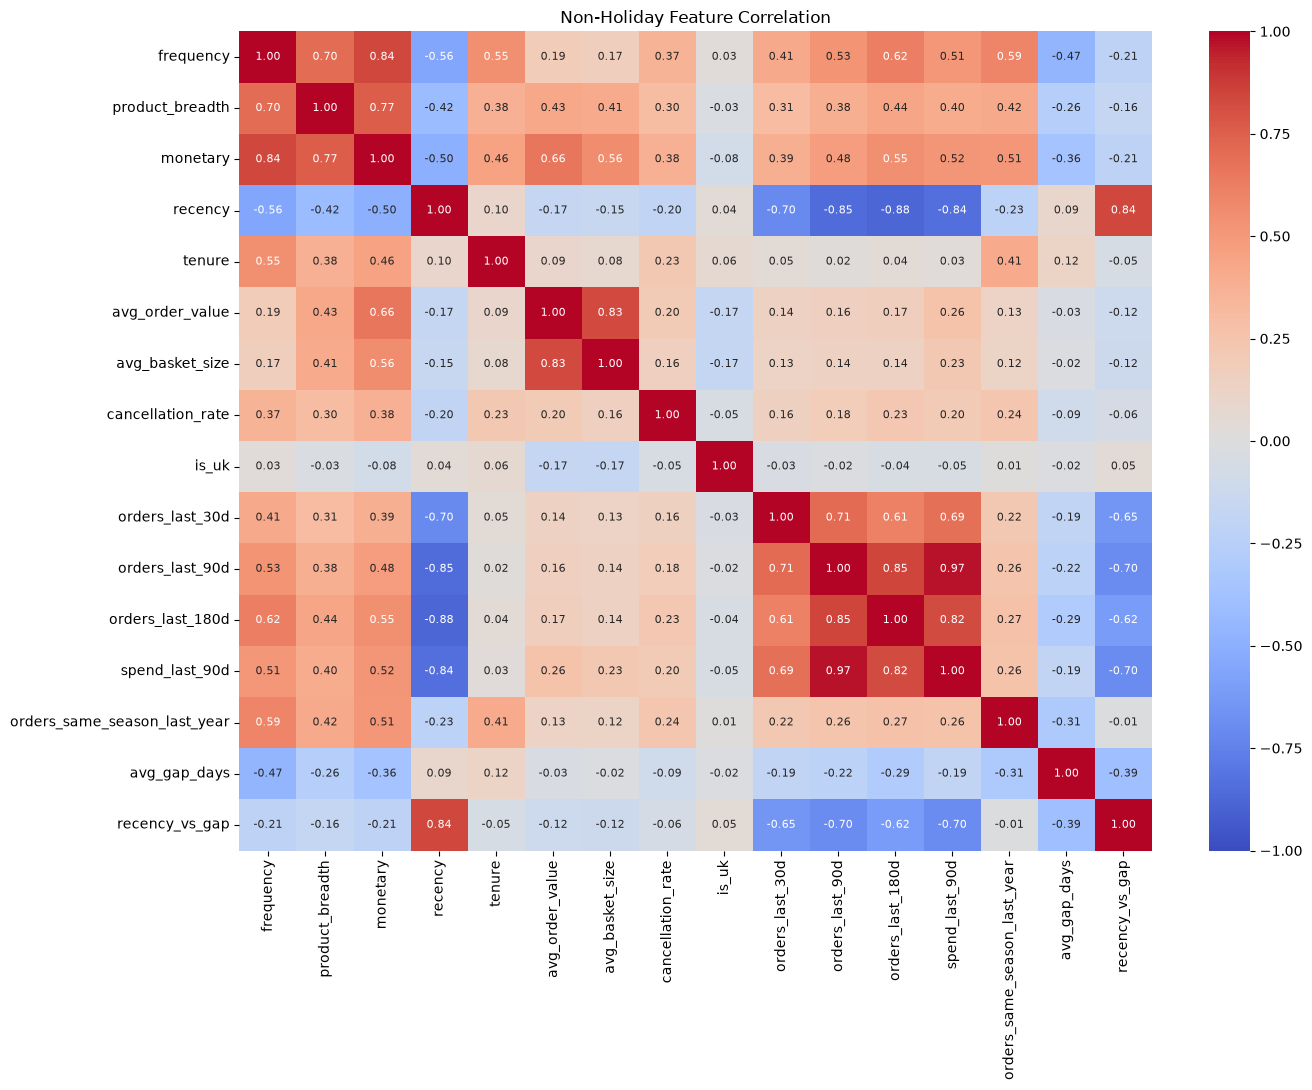

In [21]:
# Creating figure for the non-holiday heatmap
plt.figure(figsize=(14, 11))

# Draw the non-holiday heatmap
sns.heatmap(X_nonhol.corr(method='spearman'), annot=True, cmap='coolwarm', fmt=".2f",
            vmin=-1, vmax=1, annot_kws={'size': 8})

plt.title("Non-Holiday Feature Correlation")
plt.tight_layout()
plt.show()

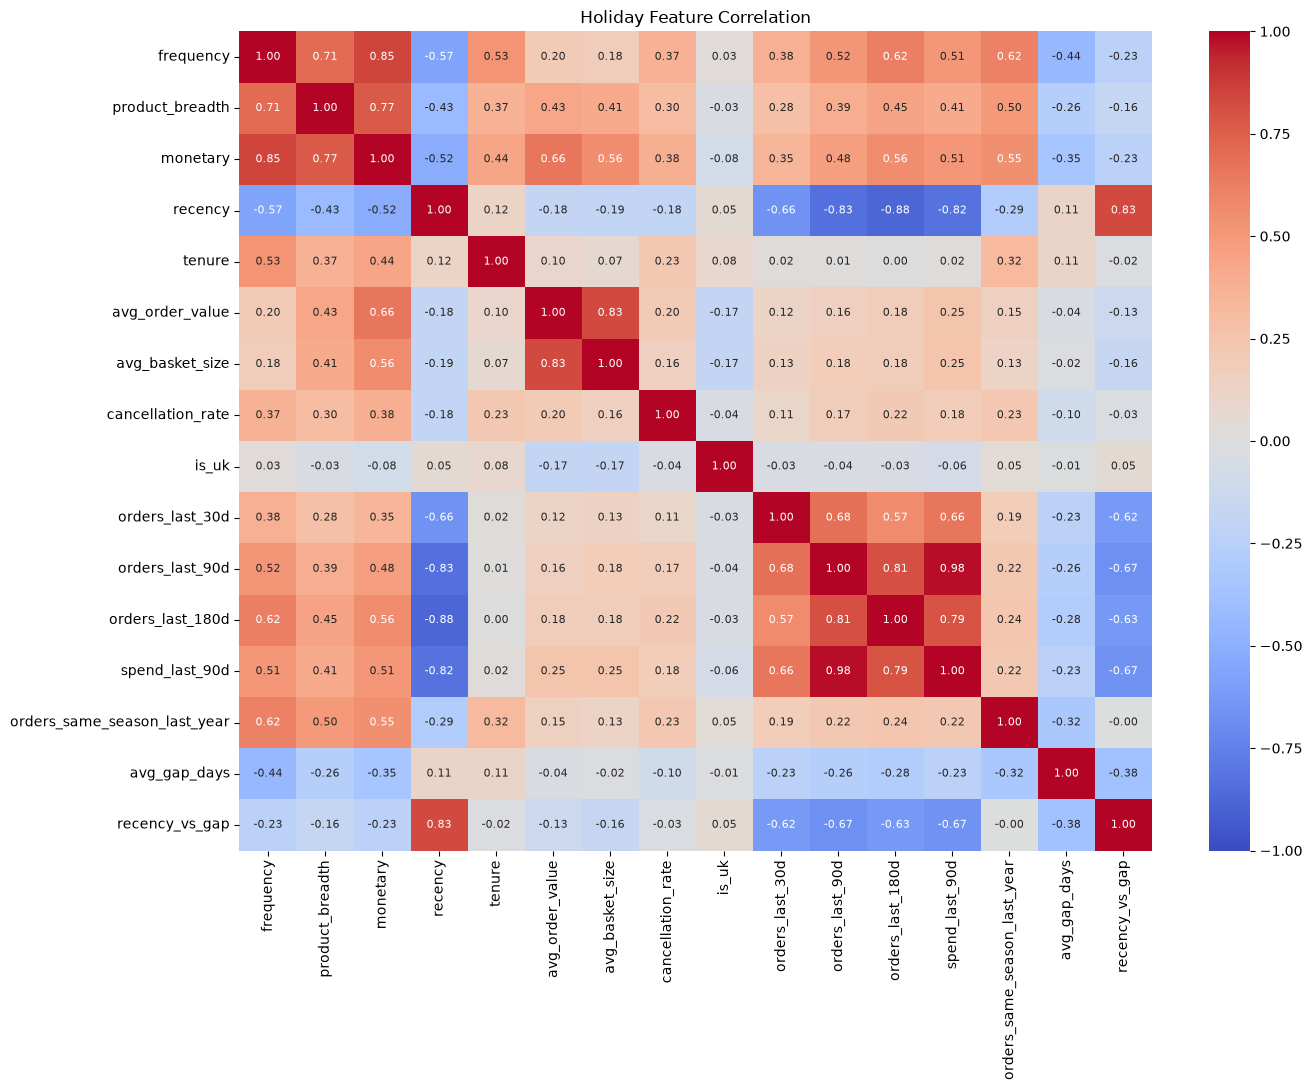

In [22]:
# Creating figure for the holiday heatmap
plt.figure(figsize=(14, 11))

# Draw the holiday heatmap
sns.heatmap(X_hol.corr(method='spearman'), annot=True, cmap='coolwarm', fmt=".2f",
            vmin=-1, vmax=1, annot_kws={'size': 8})

plt.title("Holiday Feature Correlation")
plt.tight_layout()
plt.show()

#### What the feature heatmaps show
The two heatmaps are very similar. Most pairs are within 0.05 of each other, and the biggest differences (up to about 0.09) involve orders in the same season last year, which is expected because that feature looks at a different part of last year for each cutoff. The features relate to each other in much the same way in both seasons, so the difference between the seasons is mainly in how many customers churn.

Three groups of features carry much of the same information. The first is overall buying; frequency, product breadth and monetary are linked at 0.70 to 0.85, because customers who order often also buy more products and spend more. The second is order size; average order value and basket size are linked at 0.83. The third, and strongest, is recent activity; recency, orders in the last 90 and 180 days, spend in the last 90 days and recency compared with the usual gap are all linked at 0.82 to 0.88, because a customer who bought recently has more recent orders and recent spend. Within this group, orders and spend in the last 90 days are almost the same (0.97 to 0.98). Orders in the same season last year, the average gap between orders, tenure, cancellation rate and is_uk have only weak or moderate links with the rest, so each adds something different.

One type of model we will use is tree-based. It learns by asking a series of yes/no questions, like a flowchart, for example "Has this customer been away for more than 120 days?" At each step it picks the one feature that best separates the churners from the others. If two features say almost the same thing, it uses whichever works slightly better and ignores the other, so the repeat does no harm.

The other type of model, logistic regression, gives every feature a weight that shows how much it pushes the churn risk up or down. We want to read these weights, because they can tell the CRM team things like how much each extra order lowers the risk. When two features say almost the same thing, such as frequency and monetary, the model cannot tell which one deserves the credit and may split it in a strange way. The predictions can still be good, but the weights become hard to trust.

So for logistic regression we will also try a smaller set that keeps only one feature from each linked group. If the smaller set predicts churn just as well, we keep it because it is simpler and easier to explain. If the score drops, the removed features were adding something useful and we keep all sixteen.

### Splitting The Data

We plan to test the non-holiday model on holiday customers, to see whether a separate holiday model is needed. For that test to be fair, the non-holiday model must never see those holiday test customers during training. If we split the two tables separately, the same customer could end up in the training set for one model and the test set for the other.

So we split once by customer ID. We build one list of all customers, split that list into 80% training and 20% test, and apply the same split to both tables. A customer who is hidden is hidden from both models.

When splitting, we keep the churn rate the same in the training and test groups for both seasons. To do this, each customer gets a group label made from their two churn answers, for example "1_0" means churned in the holiday window and retained in the non-holiday window. The split then shares out each group evenly.

In [23]:
# Creating a master list of customers, with their churn answer in each season side by side
ids = seg_hol[['customer_id', 'churn_90d']].merge(
    seg_nonhol[['customer_id', 'churn_90d']],
    on='customer_id',
    how='left',
    suffixes=('_hol', '_nonhol')
)

In [24]:
# Customers who only appear in the holiday table have no non-holiday answer, so they get -1
ids['churn_90d_nonhol'] = ids['churn_90d_nonhol'].fillna(-1).astype(int)

In [25]:
# Combining the two churn answers into one group label, e.g. "1_0"
ids['strata'] = ids['churn_90d_hol'].astype(str) + '_' + ids['churn_90d_nonhol'].astype(str)

# How many customers are in each group
ids['strata'].value_counts()

strata
1_1     2390
0_0     1138
0_1      972
1_0      444
0_-1     168
1_-1     141
Name: count, dtype: int64

In [26]:
# Splitting the master customer list into 80% train and 20% test
# Stratifying on the combined label keeps the churn rate the same in train and test for both seasons
train_ids, test_ids = train_test_split(
    ids, test_size=0.2, random_state=42, stratify=ids['strata']
)

In [27]:
# Creating True/False filters for the non-holiday data
train_mask_nonhol = seg_nonhol['customer_id'].isin(train_ids['customer_id'])
test_mask_nonhol = seg_nonhol['customer_id'].isin(test_ids['customer_id'])

# Applying the filters to split the non-holiday features and target
X_train_nonhol = X_nonhol[train_mask_nonhol]
X_test_nonhol = X_nonhol[test_mask_nonhol]
y_train_nonhol = y_nonhol[train_mask_nonhol]
y_test_nonhol = y_nonhol[test_mask_nonhol]

# Creating True/False filters for the holiday data
train_mask_hol = seg_hol['customer_id'].isin(train_ids['customer_id'])
test_mask_hol = seg_hol['customer_id'].isin(test_ids['customer_id'])

# Applying the filters to split the holiday features and target
X_train_hol = X_hol[train_mask_hol]
X_test_hol = X_hol[test_mask_hol]
y_train_hol = y_hol[train_mask_hol]
y_test_hol = y_hol[test_mask_hol]

In [28]:
# Checking the size and churn rate of each part
print(f"Non-holiday train: {len(X_train_nonhol):,} customers, churn {y_train_nonhol.mean():.1%}")
print(f"Non-holiday test:  {len(X_test_nonhol):,} customers, churn {y_test_nonhol.mean():.1%}")
print(f"Holiday train:     {len(X_train_hol):,} customers, churn {y_train_hol.mean():.1%}")
print(f"Holiday test:      {len(X_test_hol):,} customers, churn {y_test_hol.mean():.1%}")

Non-holiday train: 3,955 customers, churn 68.0%
Non-holiday test:  989 customers, churn 67.9%
Holiday train:     4,202 customers, churn 56.6%
Holiday test:      1,051 customers, churn 56.6%


In [29]:
# No customer should be in both the training and test lists
print("Customers in both train and test:", len(set(train_ids['customer_id']) & set(test_ids['customer_id'])))

Customers in both train and test: 0


The churn rate is almost the same in the training and test groups for both seasons (68.0% vs 67.9% for non-holiday, and 56.6% in both for holiday), and no customer appears in both groups. The test customers are a fair sample of the whole table and are hidden from both models.

## How Each Feature Relates to Churn

Here we compare customers who churned with customers who were retained, one feature at a time. Only the training customers are used, so the hidden test customers have no influence on anything we learn or decide from here on.


In [30]:
# Full rows (all columns) for the training customers only, so we can compare churners and retained customers
train_nonhol = seg_nonhol[train_mask_nonhol]
train_hol = seg_hol[train_mask_hol]

In [31]:
# Median of each feature for retained (0) and churned (1) customers, non-holiday
medians_nonhol = train_nonhol.groupby('churn_90d')[feature_cols].median().T
medians_nonhol.columns = ['Retained (0)', 'Churned (1)']
medians_nonhol.round(2)

,Retained (0),Churned (1)
frequency,6.00,2.00
product_breadth,76.00,31.00
monetary,1863.91,519.26
recency,39.00,203.00
tenure,447.00,380.00
avg_order_value,316.56,248.56
avg_basket_size,185.88,133.67
cancellation_rate,0.11,0.00
is_uk,1.00,1.00
orders_last_30d,0.00,0.00


In [32]:
# Same for the holiday training customers
medians_hol = train_hol.groupby('churn_90d')[feature_cols].median().T
medians_hol.columns = ['Retained (0)', 'Churned (1)']
medians_hol.round(2)

,Retained (0),Churned (1)
frequency,5.00,2.00
product_breadth,69.00,28.00
monetary,1516.32,487.55
recency,66.00,283.50
tenure,504.00,458.00
avg_order_value,296.82,243.09
avg_basket_size,172.83,132.40
cancellation_rate,0.09,0.00
is_uk,1.00,1.00
orders_last_30d,0.00,0.00


In [33]:
# Churn rate for customers who did and did not buy in the same season last year
print("Non-holiday:")
print(train_nonhol.groupby(train_nonhol['orders_same_season_last_year'] > 0)['churn_90d'].mean())
print()
print("Holiday:")
print(train_hol.groupby(train_hol['orders_same_season_last_year'] > 0)['churn_90d'].mean())

Non-holiday:
orders_same_season_last_year
False    0.776866
True     0.524720
Name: churn_90d, dtype: float64

Holiday:
orders_same_season_last_year
False    0.713012
True     0.444686
Name: churn_90d, dtype: float64


#### What the comparison shows

Retained customers look very different from churned ones in both seasons. The typical retained customer had placed 5 to 6 orders and last bought 39 to 66 days before the cutoff, while the typical churned customer had placed 2 orders and had been away for 203 to 284 days. Churned customers typically had no orders and no spend in the 90 and 180 days before the cutoff.

The new features show clear differences too. Retained customers usually buy every 50 to 58 days and had been away for less than their usual gap (recency compared with gap below 1), while churned customers buy less often and had been away for about twice their usual gap. Customers who bought in the same season last year churned far less; 52% against 78% in the non-holiday season, and 44% against 71% in the holiday season.

Retained customers have a higher cancellation rate. This matches the segmentation notebook, where customers with more orders also had more chances to cancel, so cancelling here is a sign of an active customer rather than an unhappy one. For orders in the last 30 days and is_uk, the medians are the same in both groups, because most customers in both groups have no orders in the last 30 days and are based in the UK. The models can still find smaller differences in these features that the median does not show.

## Baseline: How Well the RFM Total Score Ranks Churners

Before building a model, we measure how well the simple RFM total score already ranks customers by churn risk. The model is only worth using if it does better.

We measure this with AUC. If we pick one churned and one retained customer at random, AUC is the chance that the churner gets the higher risk score. An AUC of 0.5 means the score is no better than a coin flip, and 1.0 means the RFM total score completely seperating the churners from the retainers. We use AUC instead of accuracy because 68% of non-holiday customers churned, so a "model" that says everyone churns would be 68% accurate while being useless for deciding who to contact.

We also check recency on its own, since it is the simplest way to sort customers, to see whether the full RFM score adds anything beyond it.

In [34]:
from sklearn.metrics import roc_auc_score

In [35]:
# AUC of the RFM total score on the training customers
# The minus sign flips the score; since a high total score means low risk, but AUC expects high = more risk
auc_score_nonhol = roc_auc_score(train_nonhol['churn_90d'], -train_nonhol['total_score'])
auc_score_hol = roc_auc_score(train_hol['churn_90d'], -train_hol['total_score'])

print(f"Total score AUC, non-holiday: {auc_score_nonhol:.3f}")
print(f"Total score AUC, holiday:     {auc_score_hol:.3f}")

Total score AUC, non-holiday: 0.786
Total score AUC, holiday:     0.764


In [36]:
# AUC of recency alone, more days since the last order means more risk, so no minus sign is needed
auc_rec_nonhol = roc_auc_score(train_nonhol['churn_90d'], train_nonhol['recency'])
auc_rec_hol = roc_auc_score(train_hol['churn_90d'], train_hol['recency'])

print(f"Recency AUC, non-holiday: {auc_rec_nonhol:.3f}")
print(f"Recency AUC, holiday:     {auc_rec_hol:.3f}")

Recency AUC, non-holiday: 0.771
Recency AUC, holiday:     0.761


#### What the baseline shows

The RFM total score has an AUC of 0.786 in the non-holiday season and 0.764 in the holiday season. It ranks churners well above chance, so it is a fair benchmark and not an easy one to beat.

Recency on its own does almost as well; 0.771 and 0.761. Most of the total score's ranking power comes from recency, and the other parts of the score add only a little, especially in the holiday season, where the difference is 0.003. Churn is harder to predict in the holiday season with both measures, which fits the McNemar finding that many customers who look inactive in summer come back before Christmas.

These are the numbers thar our models need to beat.

## Cross-Validation: Comparing Models Without Touching the Test Customers

We will try two types of model and a few sets of features, and pick the best one. So all comparisons use cross-validation on the training customers. The training customers are split into 5 equal parts. The model learns from 4 parts and is scored on the fifth, and this is repeated 5 times so that each part is scored once. The average of the 5 AUCs tells us how good the model is, and the spread between them tells us how much the result moves by chance. If two models differ by less than this spread, we cannot say that one is better than the other.

In [37]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Split the training customers into 5 parts, keeping the churn rate the same in each part
# shuffle=True mixes the customers first, and random_state=42 gives the same parts every time
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Preparing the Features for Logistic Regression

Logistic regression needs three things done to the features before it can learn from them.

First, it cannot work with empty cells. The average gap between orders and recency compared with gap are empty for one-time buyers. We fill them with the median of the training customers, and add a 0/1 column that marks which customers had an empty cell, so the model still knows who the one-time buyers are.

Second, many features are very skewed. A few wholesalers spent over £400,000, while the typical customer spent about £750. Logistic regression treats each feature as a straight line, so those few customers would have a very large pull on the weights. We shrink large values with a log, which keeps the order of customers but pulls the very large values in. A few customers have negative total spend, because their cancellations were larger than their purchases, so we use a signed log that keeps the minus sign.

Third, the features are measured in very different units, such as days, pounds and number of orders. We rescale every feature so it has an average of 0 and a spread of 1, so no feature gets more weight just because its numbers are bigger.

These steps and the model are put together into one pipeline. The pipeline works out the medians and the scaling from the customers it is trained on only. In cross-validation, this means they are worked out again inside each part, so the part being scored never has any influence on the preparation.

In [38]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression

In [39]:
# Shrink very large values while keeping their order and their sign
# np.log1p(x) is log(1 + x), so 0 stays 0; np.sign puts the minus back for the few negative values
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

In [40]:
# A function that builds a fresh logistic regression pipeline: the preparation steps and the model in one object
def make_logreg():
    return make_pipeline(
        SimpleImputer(strategy='median', add_indicator=True),  # fill empty gaps with the median, and add a 0/1 column marking which were empty
        FunctionTransformer(signed_log),                        # shrink very large values
        StandardScaler(),                                       # put every feature on the same scale
        LogisticRegression(max_iter=1000)                       # the model; max_iter gives it enough steps to finish learning
    )

## Model 1: Logistic Regression

Logistic regression gives each feature a weight and adds them up into a churn risk between 0 and 1. We test three sets of features: all sixteen, the smaller set with one feature from each linked group, and only the nine original features from the segmentation notebook. The last one shows how much the new recent activity features add.

In [41]:
# Cross-validated AUC of logistic regression with all 16 features
lr_all_nonhol = cross_val_score(make_logreg(), X_train_nonhol, y_train_nonhol, cv=cv, scoring='roc_auc')
lr_all_hol = cross_val_score(make_logreg(), X_train_hol, y_train_hol, cv=cv, scoring='roc_auc')

# The average shows how good the model is; the spread shows how much it moves between the 5 parts
print(f"Non-holiday: {lr_all_nonhol.mean():.3f} (spread {lr_all_nonhol.std():.3f})")
print(f"Holiday:     {lr_all_hol.mean():.3f} (spread {lr_all_hol.std():.3f})")

Non-holiday: 0.819 (spread 0.010)
Holiday:     0.806 (spread 0.018)


In [42]:
# The smaller set: one feature from each linked group, plus the features that were not strongly linked to anything
small_cols = ['frequency', 'avg_order_value', 'recency', 'tenure', 'cancellation_rate', 'is_uk',
              'orders_last_30d', 'orders_same_season_last_year', 'avg_gap_days']

lr_small_nonhol = cross_val_score(make_logreg(), X_train_nonhol[small_cols], y_train_nonhol, cv=cv, scoring='roc_auc')
lr_small_hol = cross_val_score(make_logreg(), X_train_hol[small_cols], y_train_hol, cv=cv, scoring='roc_auc')

print(f"Non-holiday: {lr_small_nonhol.mean():.3f} (spread {lr_small_nonhol.std():.3f})")
print(f"Holiday:     {lr_small_hol.mean():.3f} (spread {lr_small_hol.std():.3f})")

Non-holiday: 0.811 (spread 0.011)
Holiday:     0.797 (spread 0.016)


In [43]:
# Only the 9 features from the segmentation notebook, to see how much the new recent activity features add
original_cols = ['frequency', 'product_breadth', 'monetary', 'recency', 'tenure',
                 'avg_order_value', 'avg_basket_size', 'cancellation_rate', 'is_uk']

lr_orig_nonhol = cross_val_score(make_logreg(), X_train_nonhol[original_cols], y_train_nonhol, cv=cv, scoring='roc_auc')
lr_orig_hol = cross_val_score(make_logreg(), X_train_hol[original_cols], y_train_hol, cv=cv, scoring='roc_auc')

print(f"Non-holiday: {lr_orig_nonhol.mean():.3f} (spread {lr_orig_nonhol.std():.3f})")
print(f"Holiday:     {lr_orig_hol.mean():.3f} (spread {lr_orig_hol.std():.3f})")

Non-holiday: 0.810 (spread 0.010)
Holiday:     0.791 (spread 0.016)


#### What the logistic regression results show

With all sixteen features, logistic regression has a cross-validated AUC of 0.819 in the non-holiday season and 0.806 in the holiday season. Both are clearly above the RFM total score (0.786 and 0.764).

The smaller set scores lower: 0.811 and 0.797. The drop of 0.008 and 0.009 is close to the spread between parts (0.010 to 0.018), but the smaller set is lower in both seasons, so the removed features were adding something. We keep all sixteen. This means the weights of linked features share the credit between them and should not be read one at a time, so later we explain the model by shuffling whole groups of features instead of reading single weights.

The nine original features score 0.810 and 0.791. The new recent activity features add 0.009 in the non-holiday season and 0.015 in the holiday season. The bigger gain in the holiday season fits with the feature for orders in the same season last year, which was built with that season in mind.

## Model 2: Gradient Boosting

Gradient boosting builds many small decision trees one after another. Each new tree focuses on the customers the earlier trees got wrong, and the final risk comes from adding all the trees together. Trees split customers with yes/no questions, so they are not affected by skewed values or different units, and this version of gradient boosting handles empty cells on its own. So it is given the raw features with no preparation.

Gradient boosting has settings that change how it learns, such as how many trees to build and how detailed each tree can be. Trees that are too detailed learn patterns that only fit the training customers and do not hold for new ones. We try 24 combinations of settings with the same cross-validation, and keep the one with the best average AUC.

In [44]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

In [45]:
# The settings to try; every combination is tested (2 x 3 x 2 x 2 = 24 combinations)
param_grid = {
    'learning_rate': [0.02, 0.05],       # how big a correction each new tree makes
    'max_leaf_nodes': [4, 7, 15],        # how many end points each tree can have, i.e. how detailed each tree is
    'min_samples_leaf': [50, 100],       # the fewest customers allowed at an end point, so trees cannot learn from a handful of customers
    'max_iter': [100, 200]               # how many trees to build
}

In [46]:
# Try every combination with the same 5-part cross-validation, on the non-holiday training customers
gb_search_nonhol = GridSearchCV(HistGradientBoostingClassifier(random_state=42), param_grid, cv=cv, scoring='roc_auc')
gb_search_nonhol.fit(X_train_nonhol, y_train_nonhol)

print(f"Best AUC: {gb_search_nonhol.best_score_:.3f}")
print("Best settings:", gb_search_nonhol.best_params_)

Best AUC: 0.821
Best settings: {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 4, 'min_samples_leaf': 100}


In [47]:
# The same search on the holiday training customers
gb_search_hol = GridSearchCV(HistGradientBoostingClassifier(random_state=42), param_grid, cv=cv, scoring='roc_auc')
gb_search_hol.fit(X_train_hol, y_train_hol)

print(f"Best AUC: {gb_search_hol.best_score_:.3f}")
print("Best settings:", gb_search_hol.best_params_)

Best AUC: 0.809
Best settings: {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 7, 'min_samples_leaf': 100}


In [48]:
# Spread between the 5 parts for the best settings, so we can compare it with logistic regression
best_nonhol = gb_search_nonhol.best_index_
best_hol = gb_search_hol.best_index_
gb_spread_nonhol = gb_search_nonhol.cv_results_['std_test_score'][best_nonhol]
gb_spread_hol = gb_search_hol.cv_results_['std_test_score'][best_hol]

print(f"Spread, non-holiday: {gb_spread_nonhol:.3f}")
print(f"Spread, holiday:     {gb_spread_hol:.3f}")

Spread, non-holiday: 0.008
Spread, holiday:     0.019


#### What the gradient boosting results show

The best settings give a cross-validated AUC of 0.821 in the non-holiday season and 0.809 in the holiday season. In both seasons, the best settings use small trees (4 and 7 end points) with at least 100 customers at each end point. Simple trees doing best suggests that the links between the features and churn are fairly simple, which is also what logistic regression assumes.

## Comparing the Models

All results so far, side by side. The RFM total score and recency are measured on all training customers, and the models are the average over the 5 cross-validation parts.

In [49]:
# All results side by side (AUC on the training customers; for the models, the average over the 5 parts)
comparison = pd.DataFrame({
    'Non-holiday': [auc_rec_nonhol, auc_score_nonhol, lr_orig_nonhol.mean(), lr_small_nonhol.mean(),
                    lr_all_nonhol.mean(), gb_search_nonhol.best_score_],
    'Holiday': [auc_rec_hol, auc_score_hol, lr_orig_hol.mean(), lr_small_hol.mean(),
                lr_all_hol.mean(), gb_search_hol.best_score_]
}, index=['Recency alone', 'RFM total score', 'Logistic regression, 9 original features',
          'Logistic regression, smaller set (9)', 'Logistic regression, all 16 features',
          'Gradient boosting, all 16 features'])

comparison.round(3)

,Non-holiday,Holiday
Recency alone,0.771,0.761
RFM total score,0.786,0.764
"Logistic regression, 9 original features",0.810,0.791
"Logistic regression, smaller set (9)",0.811,0.797
"Logistic regression, all 16 features",0.819,0.806
"Gradient boosting, all 16 features",0.821,0.809


#### Choosing the model

Gradient boosting is ahead of logistic regression by 0.002 in the non-holiday season and 0.003 in the holiday season. This is much smaller than the spread between the 5 parts (0.008 to 0.019), so the two models perform about the same.

We choose logistic regression with all sixteen features for both seasons. It is as good as gradient boosting here, it is simpler, it is quicker to retrain, and its risk scores are easier to explain to the CRM team. Every model beats both recency alone and the RFM total score.

From here on, we use the hidden test customers for the first time.

## Final Test on the Hidden Customers

We train the chosen model on all training customers and ask it for the churn risk of every hidden test customer. Then we compare its AUC with the RFM total score on the same customers. This is the only time the test customers are used to measure the model, so the result is a fair picture of how it would do on customers it has never seen.

We also check how sure we can be of the result. Each test group has about 1,000 customers, so the AUC would move a little with a different group of customers. To see how much, we redraw the test customers at random 1,000 times and look at how the gain over the total score changes.

In [50]:
# Train the chosen model on all training customers, one model per season
final_nonhol = make_logreg().fit(X_train_nonhol, y_train_nonhol)
final_hol = make_logreg().fit(X_train_hol, y_train_hol)

In [51]:
# Churn risk for each hidden test customer: a number between 0 and 1
# predict_proba gives two columns (chance of 0, chance of 1); [:, 1] keeps the chance of churning
risk_test_nonhol = final_nonhol.predict_proba(X_test_nonhol)[:, 1]
risk_test_hol = final_hol.predict_proba(X_test_hol)[:, 1]

In [52]:
# RFM total score of the same hidden customers, for the comparison
score_test_nonhol = seg_nonhol.loc[test_mask_nonhol, 'total_score']
score_test_hol = seg_hol.loc[test_mask_hol, 'total_score']

# AUC on the hidden customers: model against total score
print(f"Non-holiday: model {roc_auc_score(y_test_nonhol, risk_test_nonhol):.3f} | total score {roc_auc_score(y_test_nonhol, -score_test_nonhol):.3f}")
print(f"Holiday:     model {roc_auc_score(y_test_hol, risk_test_hol):.3f} | total score {roc_auc_score(y_test_hol, -score_test_hol):.3f}")

Non-holiday: model 0.851 | total score 0.806
Holiday:     model 0.809 | total score 0.778


In [53]:
# How sure can we be that the model really beats the total score?
# We redraw the test customers at random 1,000 times (the same customer can be picked more than once)
# and count how often the model's AUC is higher than the total score's AUC
def bootstrap_gain(y_true, model_risk, total_score, n_rounds=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    model_risk = np.asarray(model_risk)
    total_score = np.asarray(total_score)
    gains = []
    for _ in range(n_rounds):
        pick = rng.integers(0, len(y_true), len(y_true))   # a random redraw of the test customers
        gain = roc_auc_score(y_true[pick], model_risk[pick]) - roc_auc_score(y_true[pick], -total_score[pick])
        gains.append(gain)
    gains = np.array(gains)
    # average gain, the range that holds the middle 95% of the gains, and the share of redraws where the model won
    return gains.mean(), np.percentile(gains, 2.5), np.percentile(gains, 97.5), (gains > 0).mean()

for name, y_true, risk, score in [('Non-holiday', y_test_nonhol, risk_test_nonhol, score_test_nonhol),
                                  ('Holiday', y_test_hol, risk_test_hol, score_test_hol)]:
    gain, low, high, share = bootstrap_gain(y_true, risk, score)
    print(f"{name}: AUC gain {gain:.3f} (95% range {low:.3f} to {high:.3f}), model higher in {share:.1%} of redraws")

Non-holiday: AUC gain 0.045 (95% range 0.028 to 0.062), model higher in 100.0% of redraws
Holiday: AUC gain 0.031 (95% range 0.016 to 0.047), model higher in 100.0% of redraws


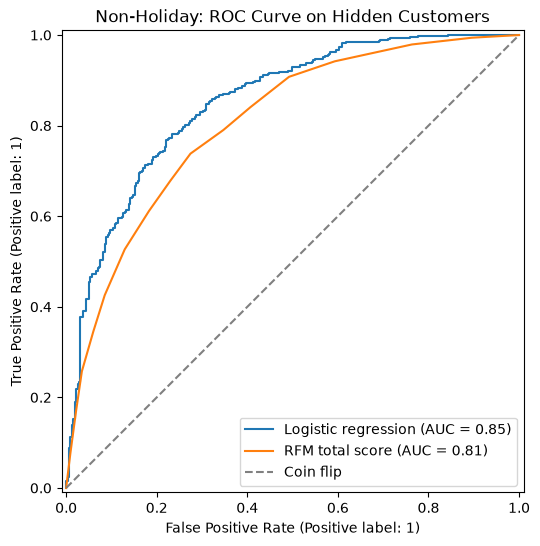

In [54]:
# ROC curve for the non-holiday hidden customers: model and total score on the same chart
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test_nonhol, risk_test_nonhol, name='Logistic regression', ax=ax)
RocCurveDisplay.from_predictions(y_test_nonhol, -score_test_nonhol, name='RFM total score', ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Coin flip')   # the line a useless score would follow
ax.set_title("Non-Holiday: ROC Curve on Hidden Customers")
ax.legend()
plt.show()

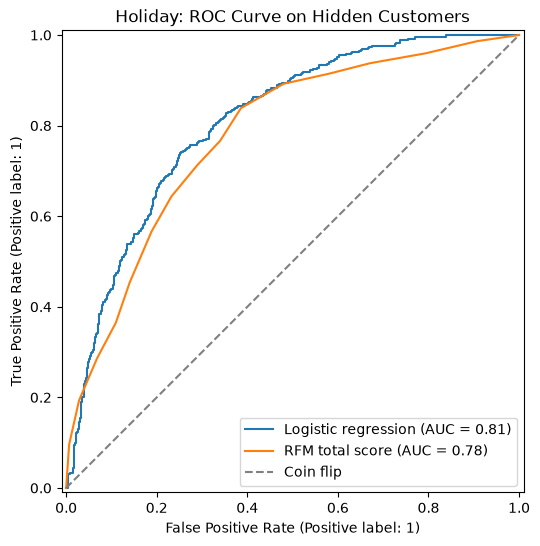

In [55]:
# ROC curve for the holiday hidden customers
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test_hol, risk_test_hol, name='Logistic regression', ax=ax)
RocCurveDisplay.from_predictions(y_test_hol, -score_test_hol, name='RFM total score', ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Coin flip')
ax.set_title("Holiday: ROC Curve on Hidden Customers")
ax.legend()
plt.show()

#### What the test shows

On the hidden customers, the model has an AUC of 0.851 in the non-holiday season and 0.809 in the holiday season. The RFM total score has 0.806 and 0.778 on the same customers. The model is ahead by 0.045 and 0.031.

Both the model and the total score do better on the test customers than in cross-validation (for example 0.806 against 0.786 for the total score in the non-holiday season). This test group happens to be a little easier to rank than the training customers. So the fair way to read the result is the gain over the total score, not the AUC on its own.

The gain holds up when the test customers are redrawn. The model was ahead in all 1,000 redraws, and the middle 95% of the gains runs from 0.028 to 0.062 in the non-holiday season and from 0.016 to 0.047 in the holiday season. The gain is modest but real.

The ROC curves show the same result as a picture. Moving down a list sorted by risk, each curve shows the share of churners found (upwards) against the share of retained customers wrongly flagged along the way (across). A curve closer to the top left corner is better, and the dashed line is what a coin flip would give. The model's curve sits above the total score's curve for most of the way.

## How Useful Are the Risk Scores?

AUC tells us how well the model ranks customers, but the CRM team will also see the risk numbers themselves, such as "this customer has a 70% chance of churning". Here we check whether those numbers can be trusted. We sort the hidden customers by risk, split them into 10 equal groups, and compare the average predicted risk in each group with the share of customers who actually churned.

We also look at what the team gets if it contacts the riskiest 20% of customers, and at a simple yes/no version of the model, where anyone with a risk of 0.5 or more is called a churner.

In [56]:
# Split the hidden customers into 10 equal groups by churn risk, and compare the predicted risk with what really happened
def risk_groups(y_true, risk):
    table = pd.DataFrame({'churned': np.asarray(y_true), 'risk': np.asarray(risk)})
    # rank(method='first') breaks ties, so qcut can make 10 equal groups; group 10 = highest risk
    table['risk_group'] = pd.qcut(table['risk'].rank(method='first'), 10, labels=range(1, 11))
    return table.groupby('risk_group', observed=True).agg(
        customers=('churned', 'size'),
        predicted_churn=('risk', 'mean'),
        actual_churn=('churned', 'mean')
    ).round(3)

risk_groups(y_test_nonhol, risk_test_nonhol)

,customers,predicted_churn,actual_churn
risk_group,,,
1,99,0.109,0.071
2,99,0.324,0.384
3,99,0.482,0.444
4,99,0.630,0.646
5,99,0.730,0.737
6,98,0.802,0.796
7,99,0.860,0.879
8,99,0.899,0.939
9,99,0.924,0.949


In [57]:
# The same table for the holiday hidden customers
risk_groups(y_test_hol, risk_test_hol)

,customers,predicted_churn,actual_churn
risk_group,,,
1,106,0.066,0.028
2,105,0.211,0.248
3,105,0.337,0.381
4,105,0.462,0.448
5,105,0.580,0.581
6,105,0.669,0.714
7,105,0.746,0.724
8,105,0.806,0.810
9,105,0.864,0.867


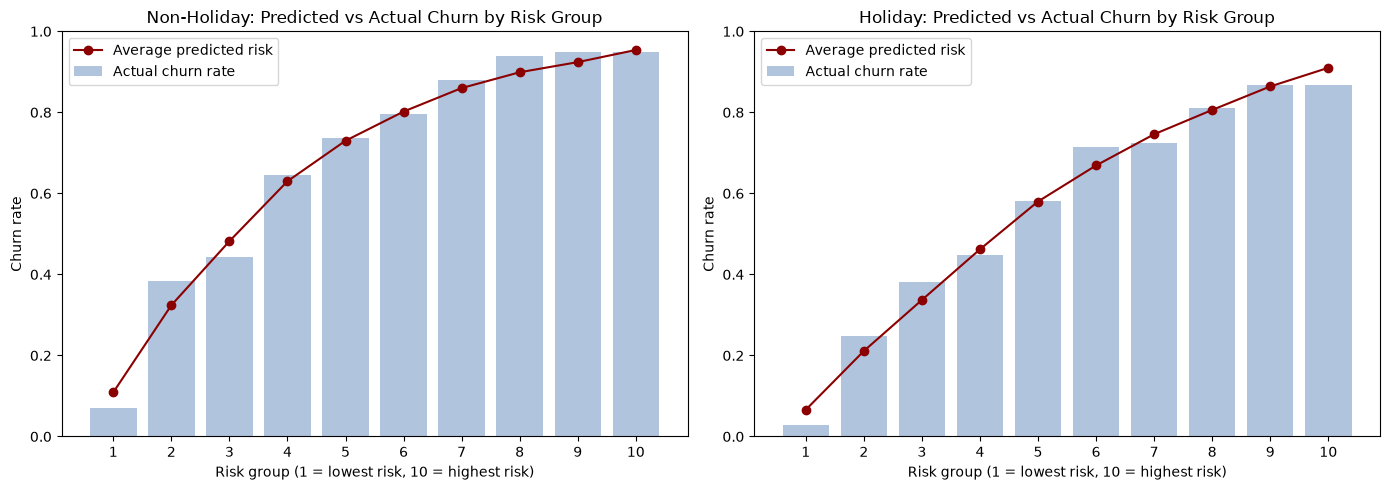

In [58]:
# Draw predicted against actual churn for each risk group, for both seasons
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, y_true, risk) in zip(axes, [('Non-Holiday', y_test_nonhol, risk_test_nonhol),
                                          ('Holiday', y_test_hol, risk_test_hol)]):
    groups = risk_groups(y_true, risk)
    ax.bar(groups.index.astype(str), groups['actual_churn'], color='lightsteelblue', label='Actual churn rate')
    ax.plot(groups.index.astype(str), groups['predicted_churn'], color='darkred', marker='o', label='Average predicted risk')
    ax.set_title(f"{name}: Predicted vs Actual Churn by Risk Group")
    ax.set_xlabel("Risk group (1 = lowest risk, 10 = highest risk)")
    ax.set_ylabel("Churn rate")
    ax.set_ylim(0, 1)
    ax.legend()

plt.tight_layout()
plt.show()

In [59]:
# Churners caught if the CRM team contacts the riskiest 20% of customers: model against total score
def share_caught(y_true, risk, top_share=0.2):
    table = pd.DataFrame({'churned': np.asarray(y_true), 'risk': np.asarray(risk)})
    top = table.sort_values('risk', ascending=False).head(int(len(table) * top_share))   # the riskiest 20%
    return top['churned'].sum() / table['churned'].sum()                               # share of all churners found in that group

for name, y_true, risk, score in [('Non-holiday', y_test_nonhol, risk_test_nonhol, score_test_nonhol),
                                  ('Holiday', y_test_hol, risk_test_hol, score_test_hol)]:
    # rank(method='first') breaks ties in the total score, which only has 16 possible values
    score_risk = (-score).rank(method='first')
    # the most any score could catch: the riskiest 20% can hold at most that many customers
    most_possible = min(1, int(len(y_true) * 0.2) / np.asarray(y_true).sum())
    print(f"{name}: model {share_caught(y_true, risk):.1%} | total score {share_caught(y_true, score_risk):.1%} "
          f"| most possible {most_possible:.1%} of churners in the riskiest 20%")

Non-holiday: model 27.8% | total score 27.2% | most possible 29.3% of churners in the riskiest 20%
Holiday: model 30.6% | total score 29.6% | most possible 35.3% of churners in the riskiest 20%


In [60]:
# Confusion matrix and the four yes/no metrics at a cut-off of 0.5: customers with a risk of 0.5 or more are called churners
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

for name, y_true, risk in [('Non-holiday', y_test_nonhol, risk_test_nonhol), ('Holiday', y_test_hol, risk_test_hol)]:
    predicted = (risk >= 0.5).astype(int)
    matrix = pd.DataFrame(confusion_matrix(y_true, predicted),
                          index=['Actually retained', 'Actually churned'],
                          columns=['Predicted retained', 'Predicted churned'])
    print(name)
    print(matrix)
    # accuracy: the share of all customers the model got right
    # the "everyone churns" figure is what a model that does nothing would get, for comparison
    print(f"Accuracy  {accuracy_score(y_true, predicted):.1%} (saying everyone churns would give {y_true.mean():.1%})")
    # precision: of the customers called churners, the share who did churn
    print(f"Precision {precision_score(y_true, predicted):.1%}")
    # recall: of the customers who did churn, the share the model called churners
    print(f"Recall    {recall_score(y_true, predicted):.1%}")
    # F1: one number that balances precision and recall; it is only high when both are high
    print(f"F1 score  {f1_score(y_true, predicted):.3f}")
    print()

Non-holiday
                   Predicted retained  Predicted churned
Actually retained                 191                126
Actually churned                   71                601
Accuracy  80.1% (saying everyone churns would give 67.9%)
Precision 82.7%
Recall    89.4%
F1 score  0.859

Holiday
                   Predicted retained  Predicted churned
Actually retained                 294                162
Actually churned                  103                492
Accuracy  74.8% (saying everyone churns would give 56.6%)
Precision 75.2%
Recall    82.7%
F1 score  0.788



#### What the risk groups show

The predicted risk is close to the real churn rate in every group, within about 6 percentage points. The lowest risk group churned 7% of the time in the non-holiday season and 3% in the holiday season, and the highest risk group churned 95% and 87% of the time. So when the model says a customer has a 70% risk, about 70% of customers like them do churn, and the CRM team can read the numbers as they are.

In the riskiest 20% of customers, the model and the total score find almost the same share of churners (27.8% against 27.2% in the non-holiday season, 30.6% against 29.6% in the holiday season). Most customers churn, so the riskiest 20% is almost all churners whichever way we rank. In the non-holiday season, both are close to the most possible (29.3%). In the holiday season, the most possible is 35.3%, so there is more room, and the model is 1 point ahead. The model's advantage is not at the very top of the list but in the middle, where the total score has only 16 possible values and puts many different customers on the same score. The model separates those customers.

With a cut-off of 0.5, the model flags most customers as churners, because most customers do churn. In the non-holiday season, it gets 80.1% of customers right (accuracy), 82.7% of the customers it flags do churn (precision), and it finds 89.4% of all churners (recall), giving an F1 score of 0.859. In the holiday season, these are 74.8%, 75.2%, 82.7% and 0.788.

Accuracy needs care here. A model that simply says every customer churns would already be 67.9% accurate in the non-holiday season and 56.6% in the holiday season. So the model's real gain in accuracy is about 12 points in the non-holiday season (80.1% against 67.9%) and 18 points in the holiday season (74.8% against 56.6%). The cut-off of 0.5 is also a choice, and it can be moved to match how many customers the team can contact. This is why the ranked list, and AUC as the main measure, are more useful to the team than a single yes/no answer.

## Is One Model Enough for Both Seasons?

To answer this, each model scores the other season's hidden customers, using that season's features. If the non-holiday model does as well on holiday customers as the holiday model does, one model would be enough. We check two things: how well each model ranks the customers (AUC), and whether its risk numbers match the real churn rate.

Because the split was shared between the seasons, none of these hidden customers was seen by either model during training, so the comparison is fair.

In [61]:
# Each model scores the other season's hidden customers, using that season's own features
nonhol_model_on_hol = final_nonhol.predict_proba(X_test_hol)[:, 1]
hol_model_on_nonhol = final_hol.predict_proba(X_test_nonhol)[:, 1]

In [62]:
# Ranking: AUC of both models on the same hidden customers
print("Holiday hidden customers:")
print(f"  Holiday model:     AUC {roc_auc_score(y_test_hol, risk_test_hol):.3f}")
print(f"  Non-holiday model: AUC {roc_auc_score(y_test_hol, nonhol_model_on_hol):.3f}")
print()
print("Non-holiday hidden customers:")
print(f"  Non-holiday model: AUC {roc_auc_score(y_test_nonhol, risk_test_nonhol):.3f}")
print(f"  Holiday model:     AUC {roc_auc_score(y_test_nonhol, hol_model_on_nonhol):.3f}")

Holiday hidden customers:
  Holiday model:     AUC 0.809
  Non-holiday model: AUC 0.806

Non-holiday hidden customers:
  Non-holiday model: AUC 0.851
  Holiday model:     AUC 0.843


In [63]:
# Risk level: the average predicted risk against the real churn rate
print("Holiday hidden customers, real churn rate:", f"{y_test_hol.mean():.1%}")
print(f"  Holiday model predicts:     {risk_test_hol.mean():.1%}")
print(f"  Non-holiday model predicts: {nonhol_model_on_hol.mean():.1%}")
print()
print("Non-holiday hidden customers, real churn rate:", f"{y_test_nonhol.mean():.1%}")
print(f"  Non-holiday model predicts: {risk_test_nonhol.mean():.1%}")
print(f"  Holiday model predicts:     {hol_model_on_nonhol.mean():.1%}")

Holiday hidden customers, real churn rate: 56.6%
  Holiday model predicts:     56.5%
  Non-holiday model predicts: 66.6%

Non-holiday hidden customers, real churn rate: 67.9%
  Non-holiday model predicts: 67.1%
  Holiday model predicts:     57.6%


#### One model or two?

For ranking, one model would be enough. On the holiday hidden customers, the non-holiday model has an AUC of 0.806 against 0.809 for the holiday model. On the non-holiday hidden customers, the holiday model has 0.843 against 0.851 for the non-holiday model. The differences (0.003 and 0.008) are small, so the order of customers from high to low risk is almost the same whichever model is used.

For the risk numbers, two models are needed. On the holiday customers, the non-holiday model predicts an average risk of 66.6%, while only 56.6% actually churned. It expects about 10 percentage points more churn than really happens, because it learned from the summer period, when more customers stayed away. The holiday model predicts 56.5%, which matches. The same happens the other way round: the holiday model predicts 57.6% for the non-holiday customers, against a real churn rate of 67.9%.

So we keep two models. The CRM team uses the risk numbers to work out value at risk and to decide how many customers to contact, and those numbers are only right when the model matches the season. This agrees with the McNemar test in the segmentation notebook: customers behave differently before Christmas, and the difference shows up mainly in how many customers churn, not in which customers are more likely to churn.

## What Drives the Predictions

Because the sixteen features include linked groups, the weights of single features are hard to read. Instead, we measure how much the model relies on each group of features. We take the hidden customers and shuffle the values of one group between customers, so that group no longer tells the model anything real, and see how much the AUC drops. A big drop means the model relies on that group.

Features in the same linked group are shuffled together. If we shuffled one of them alone, the model could still get the same information from the others in its group, and the feature would look less important than it is. Each shuffle is repeated 20 times and the drops are averaged.

In [64]:
# The linked groups from the heatmaps; features in the same group are shuffled together
# Recent activity: recency, orders in the last 30/90/180 days, spend in the last 90 days, recency vs gap
# Overall buying: frequency, product breadth, monetary
# Order size: average order value, basket size
feature_groups = {
    'Recent activity': ['recency', 'orders_last_30d', 'orders_last_90d', 'orders_last_180d', 'spend_last_90d', 'recency_vs_gap'],
    'Overall buying': ['frequency', 'product_breadth', 'monetary'],
    'Order size': ['avg_order_value', 'avg_basket_size'],
    'Orders in the same season last year': ['orders_same_season_last_year'],
    'Average gap between orders': ['avg_gap_days'],
    'Tenure': ['tenure'],
    'Cancellation rate': ['cancellation_rate'],
    'Country (is_uk)': ['is_uk']
}

In [65]:
# How much the AUC drops when one group of features is shuffled (mixed up between customers)
def group_importance(model, X, y, groups, n_rounds=20, seed=42):
    rng = np.random.default_rng(seed)
    base_auc = roc_auc_score(y, model.predict_proba(X)[:, 1])   # AUC with nothing shuffled
    rows = []
    for name, cols in groups.items():
        drops = []
        for _ in range(n_rounds):
            X_shuffled = X.copy()
            order = rng.permutation(len(X))                       # a random new order of customers
            X_shuffled[cols] = X[cols].values[order]              # give every customer another customer's values for this group
            drops.append(base_auc - roc_auc_score(y, model.predict_proba(X_shuffled)[:, 1]))
        rows.append({'feature group': name, 'AUC drop': np.mean(drops)})
    return pd.DataFrame(rows).sort_values('AUC drop', ascending=False).reset_index(drop=True)

In [66]:
# Importance on the hidden customers for both seasons
importance_nonhol = group_importance(final_nonhol, X_test_nonhol, y_test_nonhol, feature_groups)
importance_hol = group_importance(final_hol, X_test_hol, y_test_hol, feature_groups)

importance = importance_nonhol.merge(importance_hol, on='feature group', suffixes=(' non-holiday', ' holiday'))
importance.round(3)

,feature group,AUC drop non-holiday,AUC drop holiday
0,Overall buying,0.100,0.033
1,Recent activity,0.076,0.086
2,Tenure,0.033,0.030
3,Orders in the same season last year,0.005,0.035
4,Average gap between orders,0.003,0.006
5,Order size,0.002,0.001
6,Cancellation rate,0.000,0.001
7,Country (is_uk),-0.000,-0.000


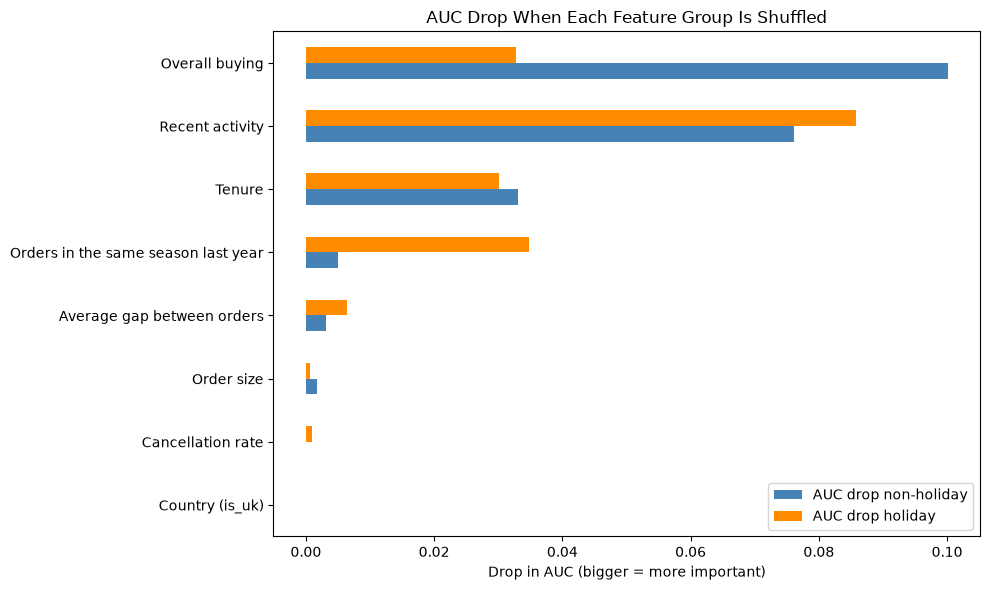

In [67]:
# Draw the importance of each group for both seasons
plot_data = importance.set_index('feature group').iloc[::-1]   # reverse so the most important group is at the top

plot_data.plot(kind='barh', figsize=(10, 6), color=['steelblue', 'darkorange'])
plt.title("AUC Drop When Each Feature Group Is Shuffled")
plt.xlabel("Drop in AUC (bigger = more important)")
plt.ylabel("")
plt.tight_layout()
plt.show()

#### What drives churn risk

In both seasons, the model relies mainly on recent activity and overall buying. Recent activity is the most important group in the holiday season (AUC drop 0.086) and the second most important in the non-holiday season (0.076). Overall buying is the most important group in the non-holiday season (0.100), but matters much less in the holiday season (0.033). Tenure matters in both seasons (0.033 and 0.030).

Orders in the same season last year makes a clear difference in the holiday season (0.035), about seven times more than in the non-holiday season (0.005). Whether a customer bought during last year's Christmas run-up is one of the better signs of whether they will buy in this one.

Order size, the average gap between orders, cancellation rate and country add very little (0.006 or less). The model could be made simpler by dropping them, but they do no harm, so we keep them for now. The direction of each feature is the one seen in the comparison of churned and retained customers: less recent activity, fewer orders and a shorter history all push the risk up.

## Ranked Customer List for the CRM Team: Check on the Hidden Customers

The customers with the highest churn risk are mostly customers who bought once, spent little and have been gone for a long time. Many of them have already left, and contacting them is unlikely to be worth the cost. What the CRM team needs is the customers where the most money is at stake.

So we rank customers by value at risk; churn risk multiplied by past spend. A customer with a 50% risk who has spent £20,000 has £10,000 at risk, while a customer with a 95% risk who has spent £200 has £190 at risk. The first customer is far more worth a phone call.

We first build the list for the hidden holiday customers only, as of the 9 September 2011 cutoff. These customers were not used to train the model, so we can check the list against what really happened. The list for all customers is built further down, after the final models are trained. In real use, the model would be run on all current customers on the day, and the column showing whether they actually churned would not exist.

In [68]:
# The hidden holiday customers with their segment, spend and churn risk
crm_list = seg_hol.loc[test_mask_hol, ['customer_id', 'segment', 'total_score', 'recency', 'frequency', 'monetary']].copy()
crm_list['churn_risk'] = risk_test_hol

# What really happened; this column only exists because these are past customers, a live list would not have it
crm_list['actually_churned'] = y_test_hol.values

# Value at risk: churn risk times past spend (negative spend counts as 0)
crm_list['value_at_risk'] = crm_list['churn_risk'] * crm_list['monetary'].clip(lower=0)

# Most value at risk first
crm_list = crm_list.sort_values('value_at_risk', ascending=False).reset_index(drop=True)
crm_list.head(15).round(2)

,customer_id,segment,total_score,recency,frequency,monetary,churn_risk,actually_churned,value_at_risk
0,15098,Loyal,14,90,3,39619.50,0.55,1,21631.97
1,12482,At Risk,15,484,27,21941.72,0.84,1,18419.94
2,14063,At Risk,15,594,7,9471.50,0.87,1,8224.46
3,12357,Lapsed,15,296,1,11229.99,0.59,0,6670.41
4,12409,Loyal,18,90,5,18235.67,0.33,0,6103.03
5,14439,At Risk,17,227,5,9443.04,0.59,1,5612.12
6,17133,Loyal,17,98,8,10558.64,0.50,0,5229.29
7,12557,Loyal,16,66,7,15106.14,0.30,0,4560.75
8,12744,Loyal,19,52,7,12158.90,0.36,0,4343.94
9,14134,At Risk,18,290,15,11123.35,0.38,1,4247.25


In [69]:
# Summary by segment: how many customers, their average risk and the total value at risk
segment_summary = crm_list.groupby('segment').agg(
    customers=('customer_id', 'size'),
    average_risk=('churn_risk', 'mean'),
    total_spend=('monetary', 'sum'),
    value_at_risk=('value_at_risk', 'sum')
).sort_values('value_at_risk', ascending=False)

segment_summary.round(2)

,customers,average_risk,total_spend,value_at_risk
segment,,,,
Loyal,218,0.38,564090.14,183710.58
At Risk,90,0.60,244239.39,142241.27
Lapsed,434,0.81,175482.00,133610.50
Champions,173,0.15,1769726.15,116792.11
Needs Attention,136,0.60,46903.20,26441.05


In [70]:
# Checking the list against what really happened (possible here because these customers are in the past)
top_by_value = crm_list.head(100)                                               # top 100 by value at risk
top_by_risk = crm_list.sort_values('churn_risk', ascending=False).head(100)     # top 100 by churn risk alone

for name, top in [('Top 100 by value at risk', top_by_value), ('Top 100 by churn risk', top_by_risk)]:
    churned = top[top['actually_churned'] == 1]
    print(f"{name}: {len(churned)} churned | past spend of all 100: £{top['monetary'].sum():,.0f} "
          f"| past spend of those who churned: £{churned['monetary'].sum():,.0f}")

Top 100 by value at risk: 46 churned | past spend of all 100: £1,028,167 | past spend of those who churned: £249,055
Top 100 by churn risk: 87 churned | past spend of all 100: £16,848 | past spend of those who churned: £16,157


#### What the ranked list shows

Ranking by value at risk points the team at very different customers from ranking by risk alone. Of the top 100 customers by risk alone, 87 churned, but together those 87 had spent only £16,157, so there was little to save. Of the top 100 by value at risk, 46 churned, and those 46 had spent £249,055. The value at risk list finds about 15 times more lost spend, even though it contains fewer churners.

By segment, Loyal customers hold the most value at risk (£183,711) even though their average risk is only 0.38, because there are many of them and they spend well. At Risk customers come second (£142,241). Lapsed customers have the highest average risk (0.81) but spent little, so they come third. Champions have the lowest average risk (0.15), but they spent so much that they still hold £116,792 at risk, so the few Champions who show signs of slowing down are worth watching.

The top of the list is mostly Loyal and At Risk customers who had spent between about £3,000 and £40,000. These are the customers the CRM team should contact first.

## Saving the Models and the List

The models were tested on customers they had not seen, and that test result is our estimate of how well they work. For real use, we retrain each model on all customers of its season, training and test together, so it learns from as many customers as possible. The test result still applies, because the method is the same and only the number of customers it learns from changes.

We save each model together with the list of features it expects, and the ranked list of the hidden holiday customers. The ranked lists for all customers are built and saved in the next section.

In [71]:
# Tool for saving Python objects to files
import joblib

# Retrain each model on all customers of its season (training and test), so it learns from as many customers as possible
model_nonhol_all = make_logreg().fit(X_nonhol, y_nonhol)
model_hol_all = make_logreg().fit(X_hol, y_hol)

# Save the models and the list of features they expect, in the same order
joblib.dump({'model': model_nonhol_all, 'features': feature_cols}, '../models/churn_model_nonholiday.joblib')
joblib.dump({'model': model_hol_all, 'features': feature_cols}, '../models/churn_model_holiday.joblib')

# Save the ranked list of the hidden holiday customers (the one checked above)
crm_list.to_csv('../outputs/crm_ranked_list_holiday_test.csv', index=False)

print("Saved: churn_model_nonholiday.joblib, churn_model_holiday.joblib, crm_ranked_list_holiday_test.csv")

Saved: churn_model_nonholiday.joblib, churn_model_holiday.joblib, crm_ranked_list_holiday_test.csv


## Ranked Customer List for All Customers

The list above covers only the 1,051 hidden holiday customers, because we needed customers the model had never seen to check it. The CRM team needs every customer scored, so we now build the list for all of them, in both seasons.

Each list uses the model retrained on all customers of its season (`model_hol_all` and `model_nonhol_all`). Every customer gets a segment, a churn risk and a value at risk (churn risk multiplied by past spend), and the list is sorted with the most value at risk first. There is no column for what really happened, because in real use it would not exist. The segment names used in the CRM reports are added next to the notebook names.

In [72]:
# Names used in the CRM reports for the segment names used in this notebook
deck_names = {'Champions': 'Top Customers', 'Loyal': 'Steady Regulars', 'Needs Attention': 'New Starters',
              'At Risk': 'Fading Big Spenders', 'Lapsed': 'Gone Quiet'}

# A function that scores every customer in a season's table and ranks them by value at risk
def make_crm_list(seg, model):
    out = seg[['customer_id', 'segment', 'total_score', 'recency', 'frequency', 'monetary']].copy()
    out['customer_group'] = out['segment'].map(deck_names)
    out['churn_risk'] = model.predict_proba(seg[feature_cols])[:, 1]                 # chance the customer places no order in the next 90 days
    out['value_at_risk'] = out['churn_risk'] * out['monetary'].clip(lower=0)         # negative spend counts as 0
    out = out.sort_values('value_at_risk', ascending=False).reset_index(drop=True)   # most value at risk first
    out.insert(0, 'rank', out.index + 1)
    return out[['rank', 'customer_id', 'customer_group', 'segment', 'total_score', 'recency', 'frequency',
                'monetary', 'churn_risk', 'value_at_risk']]

crm_list_hol_all = make_crm_list(seg_hol, model_hol_all)
crm_list_nonhol_all = make_crm_list(seg_nonhol, model_nonhol_all)

# Check that every customer is in the list, once
print(f"Holiday list: {len(crm_list_hol_all):,} customers, {crm_list_hol_all['customer_id'].nunique():,} different IDs")
print(f"Non-holiday list: {len(crm_list_nonhol_all):,} customers, {crm_list_nonhol_all['customer_id'].nunique():,} different IDs")

crm_list_hol_all.head(15).round(2)

Holiday list: 5,253 customers, 5,253 different IDs
Non-holiday list: 4,944 customers, 4,944 different IDs


,rank,customer_id,customer_group,segment,total_score,recency,frequency,monetary,churn_risk,value_at_risk
0,1,16754,Fading Big Spenders,At Risk,16,280,29,54692.82,0.49,26822.13
1,2,15098,Steady Regulars,Loyal,14,90,3,39619.50,0.66,26058.49
2,3,13902,Fading Big Spenders,At Risk,15,540,5,30375.26,0.76,22941.87
3,4,12482,Fading Big Spenders,At Risk,15,484,27,21941.72,0.84,18529.63
4,5,15749,Steady Regulars,Loyal,14,143,3,21535.90,0.63,13507.24
5,6,18251,Fading Big Spenders,At Risk,16,353,8,21964.14,0.55,11997.10
6,7,17448,Fading Big Spenders,At Risk,16,437,41,14375.01,0.73,10555.33
7,8,18052,Gone Quiet,Lapsed,11,472,1,10877.18,0.83,9067.38
8,9,14063,Fading Big Spenders,At Risk,15,594,7,9471.50,0.88,8364.74
9,10,14091,Fading Big Spenders,At Risk,12,562,2,9530.08,0.87,8308.35


In [73]:
# Summary by segment for all holiday customers: how many, their average risk and the total value at risk
segment_summary_all = crm_list_hol_all.groupby('customer_group').agg(
    customers=('customer_id', 'size'),
    average_risk=('churn_risk', 'mean'),
    total_spend=('monetary', 'sum'),
    value_at_risk=('value_at_risk', 'sum')
).sort_values('value_at_risk', ascending=False)

print(f"Average predicted risk, holiday: {crm_list_hol_all['churn_risk'].mean():.1%} (real churn rate {y_hol.mean():.1%})")
print(f"Average predicted risk, non-holiday: {crm_list_nonhol_all['churn_risk'].mean():.1%} (real churn rate {y_nonhol.mean():.1%})")
print(f"Total value at risk, holiday: £{crm_list_hol_all['value_at_risk'].sum():,.0f}")
segment_summary_all.round(2)

Average predicted risk, holiday: 56.6% (real churn rate 56.6%)
Average predicted risk, non-holiday: 68.0% (real churn rate 68.0%)
Total value at risk, holiday: £3,056,504


,customers,average_risk,total_spend,value_at_risk
customer_group,,,,
Steady Regulars,1120,0.38,2672808.48,837587.57
Fading Big Spenders,495,0.60,1417552.15,780467.60
Gone Quiet,2130,0.80,958591.10,726247.69
Top Customers,786,0.16,7887664.13,561840.47
New Starters,722,0.58,274791.25,150360.96


#### What the full lists show

Both lists cover every customer in their season, and the average predicted risk matches the real churn rate in each season.

These scores are not a test of the model. The models were retrained on all of these customers, so the results here look a little better than they would on new customers. The accuracy figures in this notebook come from the hidden customers, and those are the ones to quote. The full lists are for contacting customers, and the top of each list is where the CRM team should start.

In real use the same steps are run on the day: build the sixteen features for the new cutoff date, score them with the model for the season, and sort by value at risk.

In [74]:
# Save the ranked lists for all customers
crm_list_hol_all.round(4).to_csv('../outputs/crm_ranked_list_holiday_all.csv', index=False)
crm_list_nonhol_all.round(4).to_csv('../outputs/crm_ranked_list_nonholiday_all.csv', index=False)

print("Saved: crm_ranked_list_holiday_all.csv, crm_ranked_list_nonholiday_all.csv")

Saved: crm_ranked_list_holiday_all.csv, crm_ranked_list_nonholiday_all.csv


## Summary

#### What we built

We built two logistic regression models that predict whether a customer will place no order in the 90 days after a cutoff date: one for the non-holiday season (cutoff 10 June 2011) and one for the holiday season (cutoff 9 September 2011). Each model uses sixteen features, the nine from the segmentation notebook and seven new ones on recent activity and buying rhythm.

#### How well the models work

On customers they had never seen, the models reach an AUC of 0.851 in the non-holiday season and 0.809 in the holiday season, against 0.806 and 0.778 for the RFM total score. The gain is modest, but the model was ahead in every one of 1,000 random redraws of the test customers. The risk numbers match the real churn rates within about 6 percentage points in every risk group, so they can be used as they are.

#### The main decisions and why

Logistic regression was chosen over gradient boosting because the two performed about the same (a difference of 0.002 to 0.003, smaller than the normal spread between cross-validation parts), and logistic regression is simpler to run and to explain. All sixteen features were kept because the smaller set scored lower in both seasons. The new recent activity features added 0.009 to 0.015 AUC, and orders in the same season last year turned out to be one of the main drivers in the holiday season.

Two models are kept instead of one. Both models rank customers in almost the same order in either season, but a model used in the wrong season gets the overall churn level wrong by about 10 percentage points, and the CRM team relies on those numbers.

#### What the store should do with this

The CRM team should contact customers in order of value at risk, not churn risk alone. Ranked lists for every customer (5,253 in the holiday season and 4,944 outside it) are saved and ready to load into the CRM. The top of that list is mostly Loyal and At Risk customers with a lot of past spend, where contact is most likely to be worth it. Each season's model should be retrained once a year with the newest data, and after each 90-day window the average predicted risk should be checked against the real churn rate to catch any drift.

#### Limitations

The test customers come from the same period as the training customers. The models have not been tested on a later year, because the data covers only two years (December 2009 to December 2011), so each season's cutoff can only be used once with a full year of history before it. How well the models hold up in a new year is still unknown, and this is the first thing to check when new data arrives.

Each test group has about 1,000 customers, so AUC results can move by about 0.02 either way with a different group.

Value at risk uses total past spend, which favours long-standing customers. A measure such as spend in the last 12 months would reflect each customer's current value better.

Churn here means no order in the 90 days after the cutoff. Some customers normally order less often than that, and they can be counted as churned when they are only between orders.